# 03. Testes estatísticos e hipóteses (passos 9 a 11)

**Fase 4 do pipeline: validação de hipóteses.**

Com 130 mil registros, quase qualquer diferença dá p < 0,001. Por isso, em todos os testes
reportamos o **tamanho do efeito** (V de Cramér, razão de chances, razão de médias, pseudo-R²) com
intervalo de confiança; é ele que diz se a diferença importa.

In [1]:
import sys
import warnings
from pathlib import Path

# Encontra a raiz do projeto (a pasta que contém src/sinistros) e importa o pacote
raiz = Path.cwd()
while not (raiz / "src" / "sinistros").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

from sinistros import config, limpeza, analises as an, graficos as gr

df = limpeza.carregar()

## Passo 9. Qui-quadrado entre variáveis qualitativas

In [2]:
p9 = an.passo9_qui_quadrado(df)
pd.DataFrame({k: {c: v for c, v in p9["resumo"][k].items() if c != "descartadas"}
              for k in ["controle_com_ni", "controle", "cruzamento_com_ni", "cruzamento"]}).T

,qui2,p,gl,v_cramer,n,menor_esperado
controle_com_ni,"14,592.77",0.00,10.00,0.24,"129,617.00",7.28
controle,244.07,0.00,8.00,0.05,"50,232.00",6.43
cruzamento_com_ni,"4,775.38",0.00,12.00,0.14,"129,619.00",4.59
cruzamento,"3,628.05",0.00,10.00,0.13,"112,568.00",4.01


In [3]:
p9['perfil_ni'].round(1)

severidade,Ileso,Ferido,Fatal
controle_trafego,,,
Controle informado,32.20,66.50,1.30
Controle não informado,6.80,91.60,1.60


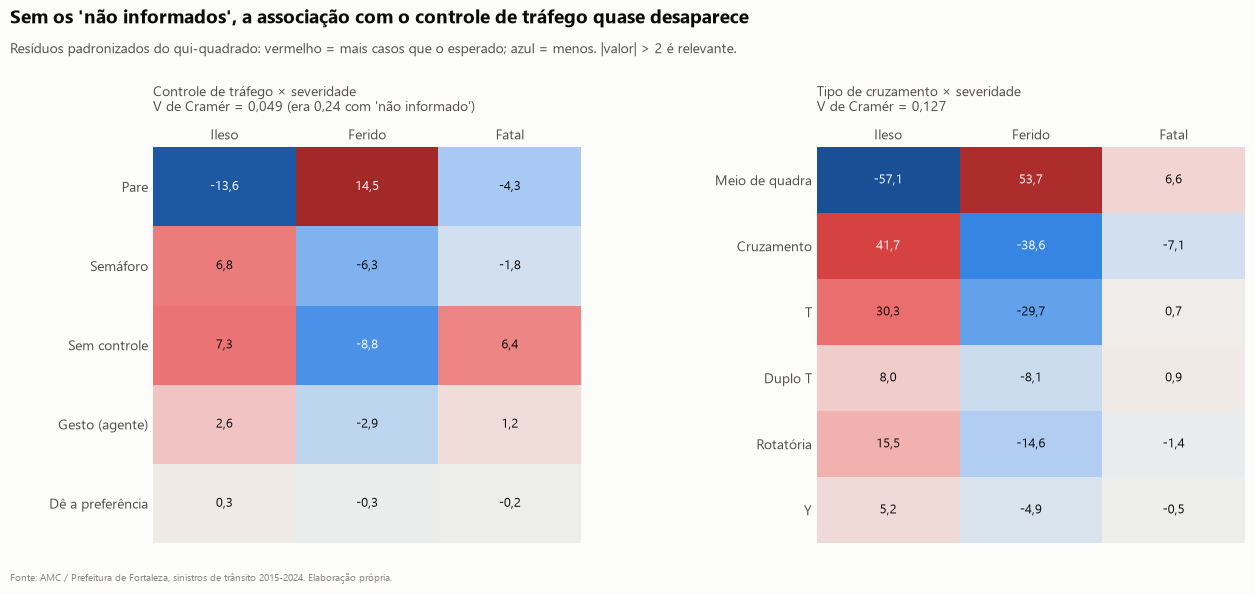

In [4]:
gr.fig16_qui_quadrado(p9);

**Resultado**
- **Controle de tráfego × severidade:** com o "não informado" como categoria, V = 0,24 (o resultado
  da versão anterior). **Sem ele, V = 0,05**, uma associação fraca. O efeito "moderado a forte" vinha
  quase todo do padrão de preenchimento: os registros sem controle informado são 91,6% "ferido",
  contra 66,5% nos demais, e eles se concentram nos anos mais recentes.
- O que sobra é coerente: locais **sem controle** têm mais acidentes fatais que o esperado (resíduo
  +6,4); com **Pare**, há mais feridos e menos ilesos.
- **Tipo de cruzamento × severidade:** V = 0,13, e o resultado se mantém sem o "não informado".
  **Meio de quadra** tem mais feridos e fatais que o esperado; **cruzamentos** e **rotatórias** têm
  mais ilesos (colisões em velocidade menor).
- Categorias com menos de 100 casos (cancela, faixa de pedestre, via férrea) foram excluídas, pois
  geravam frequências esperadas abaixo de 5.

## Passo 10. Variável quantitativa × qualitativa

In [5]:
p10 = an.passo10_quanti_quali(df)
pd.DataFrame({k: p10["resumo"][k] for k in ["natureza", "perfil"]}).T

,H,p,k,n,eta2
natureza,"9,106.73",0.00,12.00,"128,686.00",0.07
perfil,"13,416.57",0.00,6.00,"118,797.00",0.11


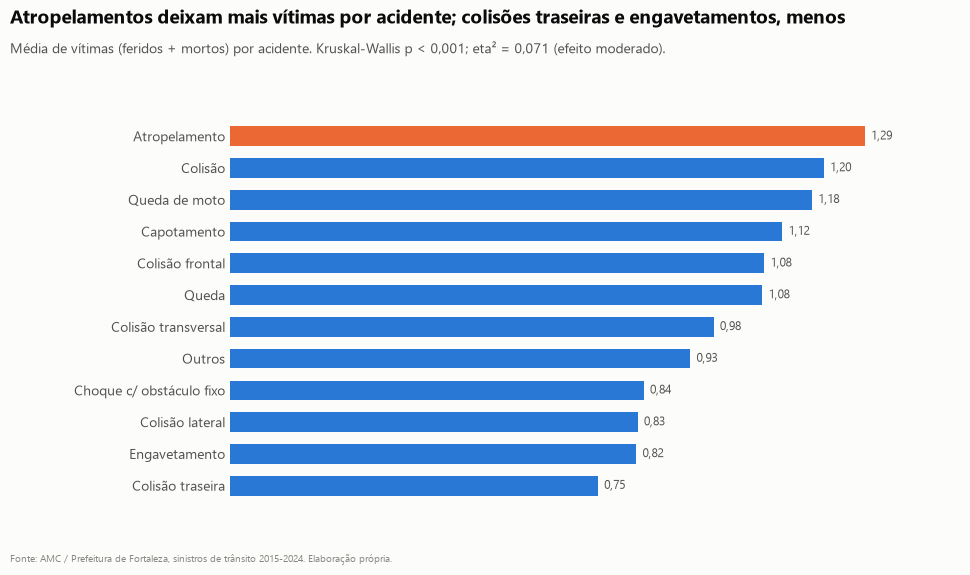

In [6]:
gr.fig17_vitimas_natureza(p10);

In [7]:
p10['medias_perfil']

,mean,count
perfil_veiculos,,
Só automóvel,0.79,29996
Só moto,1.27,27582
Moto + automóvel,1.25,45073
Envolve bicicleta,1.13,5682
Envolve ônibus/caminhão,0.80,10430
Outros,1.06,34


**Resultado**
- O número de vítimas varia com a **natureza** do acidente (Kruskal-Wallis, eta² = 0,07, efeito
  moderado) e com o **perfil de veículos** (eta² = 0,11). Atropelamentos têm a maior média de vítimas
  (1,29); colisões traseiras e engavetamentos, as menores.
- Usamos Kruskal-Wallis porque contagens de vítimas não seguem distribuição normal.

**O que mudou:** a versão anterior relatava R² = 0,44 entre feridos e severidade. Esse resultado é
**tautológico**: a severidade é definida pela presença de feridos, então é claro que ela "explica" os
feridos. Ele foi substituído por relações entre variáveis independentes.

## Passo 11. As 5 hipóteses

### H1. A letalidade é maior de madrugada e no fim de semana

- **H0:** a chance de um acidente ser fatal não depende da faixa horária nem do tipo de dia.
- **H1:** a chance é maior de madrugada e/ou no fim de semana.
- **Método:** risco relativo de cada fator separado e **regressão logística** com faixa horária, fim
  de semana, perfil de veículos e ano juntos, para separar os efeitos (por exemplo: há mais motos à
  noite?).

In [8]:
h1 = an.h1_madrugada_fim_de_semana(df)
pd.DataFrame({"madrugada": h1["resumo"]["rr_madrugada"],
              "fim de semana": h1["resumo"]["rr_fim_de_semana"]}).T

,risco_exposto_pct,risco_nao_exposto_pct,rr,rr_ic,or,or_ic,p
madrugada,2.15,1.36,1.58,"[1.419974344843955, 1.765843989687049]",1.60,"[1.4283282284821972, 1.784109733518949]",0.00
fim de semana,1.96,1.29,1.52,"[1.386823186027809, 1.6670556956367741]",1.53,"[1.3940737463738127, 1.6811671431993127]",0.00


In [9]:
h1['odds_ratios']

,coef,ic_inf,ic_sup,p
Madrugada (vs. manhã),1.90,1.65,2.19,0.00
Noite (vs. manhã),1.97,1.72,2.25,0.00
Tarde (vs. manhã),1.25,1.10,1.42,0.00
Fim de semana (vs. dia útil),1.58,1.43,1.74,0.00
Envolve bicicleta (vs. só automóvel),2.28,1.89,2.75,0.00
Envolve ônibus/caminhão (vs. só automóvel),2.72,2.34,3.16,0.00
Moto + automóvel (vs. só automóvel),0.64,0.55,0.74,0.00
Só moto (vs. só automóvel),1.77,1.55,2.02,0.00


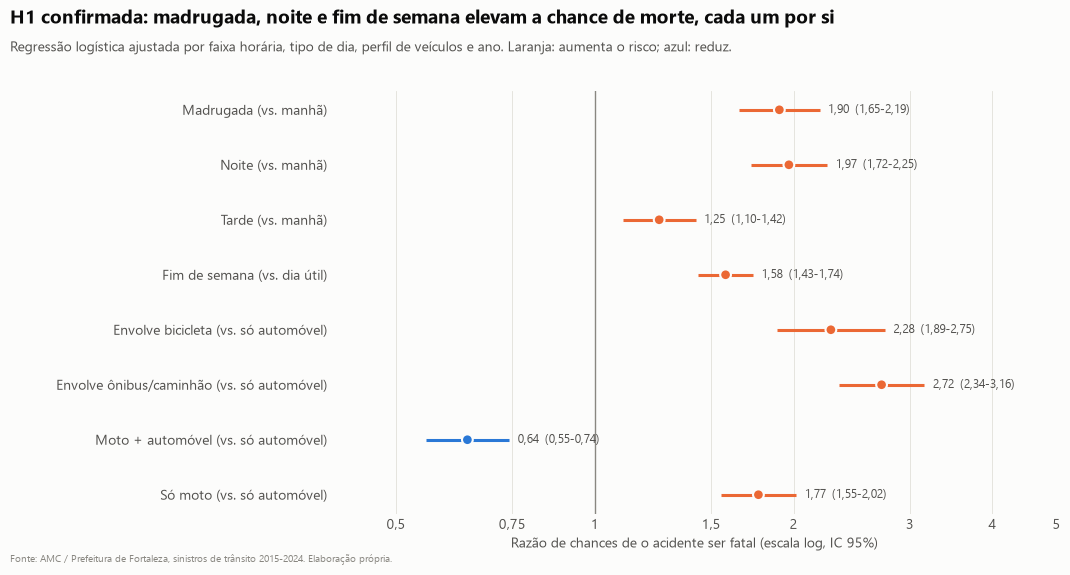

In [10]:
gr.fig18_h1(h1);

**Conclusão: H1 confirmada.**
- Separados: acidente de madrugada tem risco de morte 1,58 vez maior (IC 1,42-1,77); no fim de
  semana, 1,52 vez (IC 1,39-1,67).
- Ajustados: **madrugada OR 1,90** e **noite OR 1,97** em relação à manhã; **fim de semana OR 1,58**.
  Os efeitos se mantêm com controle de veículos e ano, e a interação faixa × fim de semana não é
  significativa (p = 0,06): os dois fatores somam.
- O modelo também mostra que acidentes que envolvem ônibus/caminhão (OR 2,72), bicicleta (OR 2,28)
  ou só moto (OR 1,77) são mais letais que os só com automóvel. "Moto + automóvel" é menos letal
  (OR 0,64), provavelmente porque "só automóvel" e "só moto" incluem os atropelamentos (o pedestre
  não é registrado como veículo).

**O que mudou:** a versão anterior juntava "madrugada OU fim de semana" num único grupo e reportava
V = 0,029; isso escondia que os dois efeitos são separados e de tamanho relevante (risco 50-90% maior).
A causa (álcool, velocidade) não é testada aqui: os dados não têm essa informação.

### H2. A presença de motos aumenta o número de vítimas

- **H0:** o número de vítimas não difere entre os perfis de veículos.
- **H1:** acidentes com moto têm mais vítimas.
- **Método:** risco relativo de haver vítima e **regressão de Poisson** do número de vítimas por
  perfil, com erros robustos e ajuste por ano.

In [11]:
h2 = an.h2_motos_feridos(df)
print(f"Com moto: {h2['resumo']['pct_com_vitima_moto']:.1f}% têm vítima; "
      f"sem moto: {h2['resumo']['pct_com_vitima_sem_moto']:.1f}% "
      f"(RR {h2['resumo']['rr_vitima_moto']:.2f})")
h2["irr"]

Com moto: 96.5% têm vítima; sem moto: 60.3% (RR 1.60)


,coef,ic_inf,ic_sup,p
Envolve bicicleta,1.45,1.42,1.47,0.00
Envolve ônibus/caminhão,1.00,0.98,1.03,0.80
Moto + automóvel,1.59,1.57,1.61,0.00
Só moto,1.62,1.60,1.64,0.00


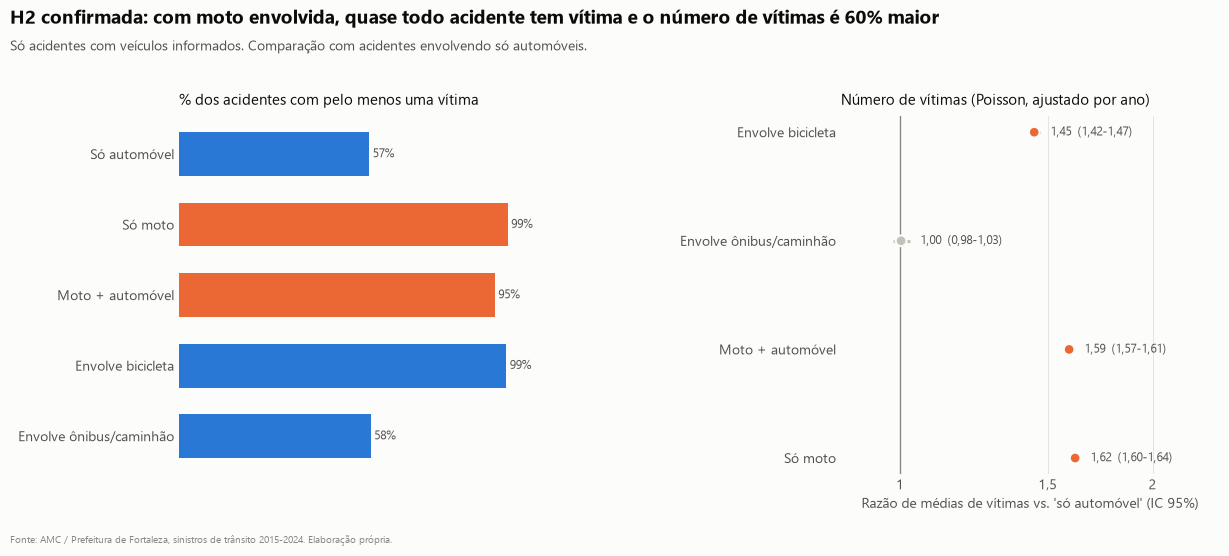

In [12]:
gr.fig19_h2(h2);

**Conclusão: H2 confirmada.**
- Com moto envolvida, **96,5%** dos acidentes têm ao menos uma vítima, contra 60,3% sem moto
  (RR 1,60).
- O número médio de vítimas é **62% maior** em acidentes só com moto e 59% maior com moto + automóvel,
  em relação a acidentes só com automóveis.
- Cautela: parte da diferença pode vir do registro. Batidas só entre carros, sem feridos, tendem a
  ser menos registradas pela AMC, o que reduz a proporção de acidentes sem vítima entre os de carro.

**O que mudou:** o ANOVA anterior assumia normalidade em contagens; aqui usamos Poisson com erros
robustos (a variância é menor que a média: dispersão 0,45). E excluímos os acidentes sem veículos
informados.

### H3. Os acidentes caem ao longo do tempo

- **H0:** não há mudança no número de acidentes ao longo do tempo.
- **H1:** há queda.
- **Método:** (1) busca da quebra estrutural com teste de Chow em todos os meses (sem os meses de
  pandemia); (2) modelo com dois patamares, tendência em cada período, sazonalidade mensal e efeito
  da pandemia, com erros HAC (robustos à autocorrelação); (3) tendência das mortes com Poisson.

In [13]:
h3 = an.h3_tendencia(df)
pd.Series(h3["resumo"]).to_frame("valor")

,valor
quebra_mes,2018-01
quebra_F,58.46
r2_linear,0.42
r2_segmentado,0.78
degrau_mensal,-584.94
degrau_p,0.00
tendencia_antes_mes,-3.31
tendencia_antes_p,0.23
tendencia_depois_mes,0.41
covid_mensal,-200.35


In [14]:
h3['busca_quebra'].sort_values('F', ascending=False).head()

,mes,F,p
24,2018-01-01,58.46,0.00
25,2018-02-01,57.60,0.00
23,2017-12-01,53.64,0.00
22,2017-11-01,50.31,0.00
27,2018-04-01,48.63,0.00


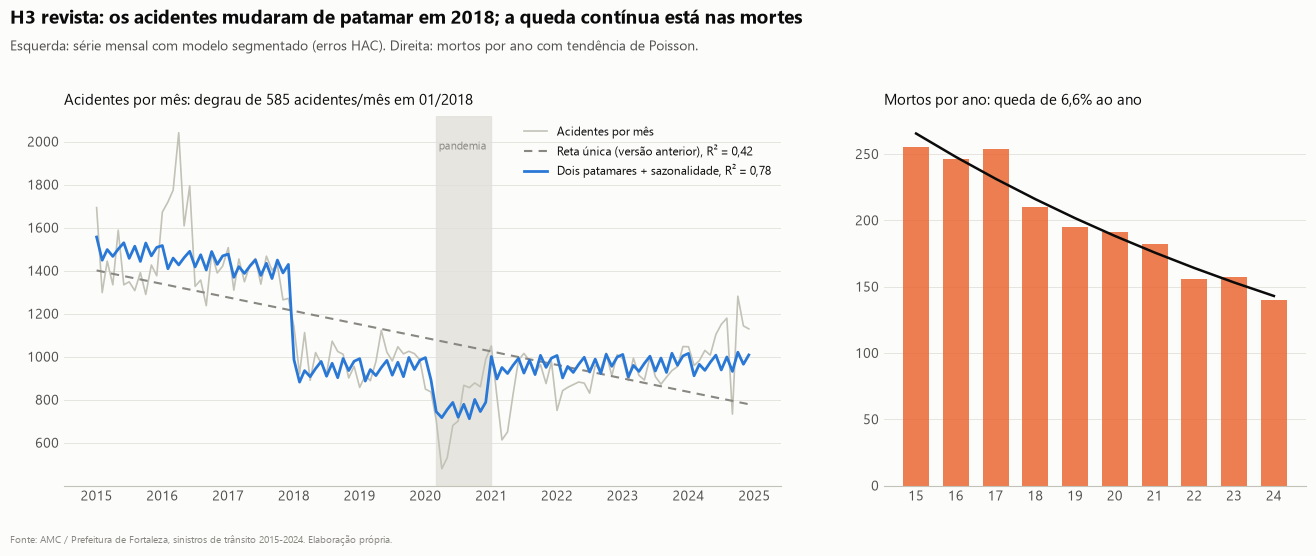

In [15]:
gr.fig20_h3(h3);

**Conclusão: H3 revista.**
- A série não tem uma queda contínua: tem **um degrau em janeiro de 2018** (F de Chow = 58, muito
  acima do valor crítico de Andrews, por volta de 12 a 5%). A média mensal passa de 1.453 para
  958 acidentes (sem os meses de pandemia).
- Dentro de cada período, **não há tendência** significativa (antes: −3,3/mês, p = 0,23; depois:
  +0,4/mês). A pandemia tirou cerca de 200 acidentes por mês entre março e dezembro de 2020.
- O modelo segmentado explica 78% da variação (R² 0,78); a reta única da versão anterior explicava 42%
  e sugeria uma queda gradual que os dados não mostram.
- Uma mudança tão abrupta, num único mês, é típica de **mudança no registro** (sistema, critério ou
  fonte), não de mudança de comportamento. As **mortes**, menos sensíveis ao critério de registro, não
  têm degrau (F máximo 4,5) e caem de forma contínua: **−6,6% ao ano** (IC −8,1% a −5,2%).
- **Recomendação:** confirmar com a AMC o que mudou em janeiro de 2018.

### H4. O tipo de controle de tráfego se associa à gravidade

- **H0:** a chance de morte não depende do controle de tráfego do local.
- **H1:** depende.
- **Método:** só os 39% dos acidentes com controle informado. Letalidade por tipo de controle e
  regressão logística (semáforo × Pare × sem controle) ajustada por faixa horária, fim de semana e ano.

In [16]:
h4 = an.h4_controle_trafego(df)
h4['letalidade']

,n,eventos,pct,ic_inf,ic_sup
controle_trafego,,,,,
Pare,20576,214,1.04,0.91,1.19
Semáforo,15759,183,1.16,1.01,1.34
Sem controle,13490,245,1.82,1.60,2.06
Gesto (agente),597,11,1.84,1.03,3.27
Dê a preferência,496,6,1.21,0.56,2.61


In [17]:
h4['odds_ratios']

,coef,ic_inf,ic_sup,p
Pare (vs. semáforo),1.02,0.83,1.24,0.86
Sem controle (vs. semáforo),1.62,1.33,1.96,0.00


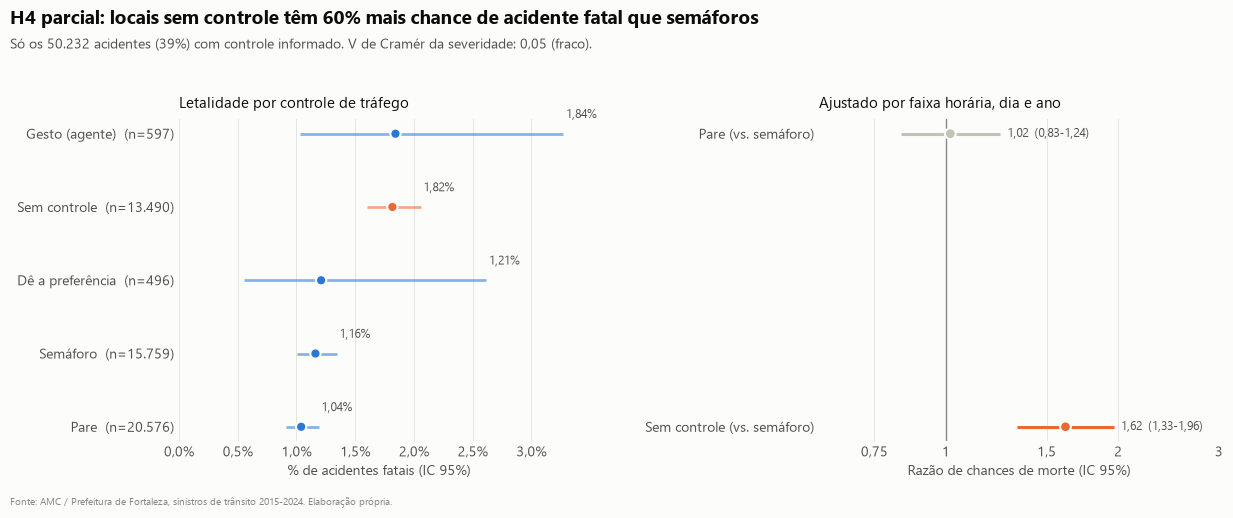

In [18]:
gr.fig21_h4(h4);

**Conclusão: H4 parcialmente confirmada.**
- A associação geral é **fraca** (V = 0,05, não 0,24).
- Mas há um efeito específico: em locais **sem controle**, a chance de o acidente ser fatal é **62%
  maior** que em semáforos (OR 1,62; IC 1,33-1,96), mesmo ajustando por horário, dia e ano. Pare e
  semáforo não diferem (OR 1,02).
- Limites: vale só para os 39% com a informação, e o preenchimento piorou com o tempo. Locais sem
  controle também podem ser vias mais rápidas; o dado não permite separar as duas coisas.

### H5. A exposição (população e malha viária) explica os acidentes por bairro

- **H0:** o número de acidentes de um bairro não se relaciona com sua população e sua malha viária.
- **H1:** relaciona-se.
- **Método:** regressão **Binomial Negativa** (adequada a contagens com variância maior que a média)
  com variáveis **externas** à base: população (IBGE, Censo 2022), km de vias e cruzamentos por km
  (OpenStreetMap). Comparação de modelos por pseudo-R² (deviance explicada) e AIC.

In [19]:
h5 = an.h5_bairros(df)
h5["comparacao"]

,pseudo_r2,aic,alpha
modelo,,,
População,0.34,"1,861.37",0.38
Km de vias,0.37,"1,857.21",0.37
População + km de vias,0.39,"1,855.19",0.36
População + km de vias + cruzamentos/km,0.42,"1,850.22",0.34


In [20]:
h5['coeficientes']

,coef,ic_inf,ic_sup,p
log(população),0.40,0.13,0.67,0.00
log(km de vias),0.41,0.13,0.69,0.00
log(cruzamentos por km),-1.03,-1.72,-0.35,0.00


In [21]:
h5["bairros"].sort_values("razao_obs_esp", ascending=False)[
    ["bairro", "acidentes", "esperado", "razao_obs_esp", "populacao", "km_vias"]].head(10)

,bairro,acidentes,esperado,razao_obs_esp,populacao,km_vias
95,Centro,7257,"1,718.49",4.22,24096,85.50
68,Aldeota,5404,"2,016.24",2.68,42580,81.18
46,Meireles,4127,"1,572.83",2.62,38374,51.13
92,José Bonifácio,1567,605.45,2.59,8539,18.62
60,Fátima,3384,"1,396.08",2.42,23114,56.27
117,Parangaba,3544,"1,514.65",2.34,28060,58.61
70,Montese,2581,"1,144.97",2.25,21794,38.25
90,Aeroporto,1733,795.87,2.18,8995,32.35
88,Benfica,1842,854.37,2.16,12511,29.96
25,Dionísio Torres,1927,969.67,1.99,13875,36.61


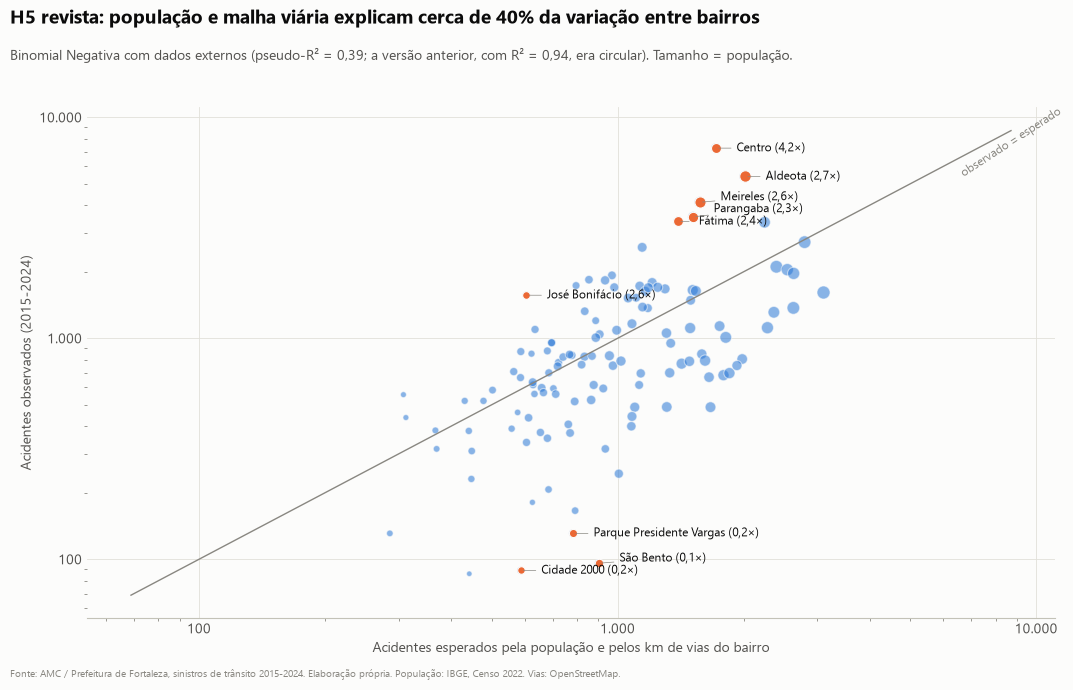

In [22]:
gr.fig22_h5(h5);

**Conclusão: H5 revista.**
- População e km de vias explicam cerca de **39%** da variação entre bairros (pseudo-R² 0,39; 0,42
  incluindo cruzamentos por km). É uma relação real e significativa, mas **não** os 95% da versão
  anterior.
- O R² de 0,95 anterior era **circular**: usava como preditor a soma de motos *envolvidas nos próprios
  acidentes* de cada bairro, que cresce junto com o número de acidentes por construção. Reproduzindo
  essa conta, o R² dá 0,94, sem dizer nada sobre a causa.
- Mais cruzamentos por km de via se associam a **menos** acidentes, com população e km de vias fixos:
  malhas de ruas curtas (bairros residenciais) contra vias longas e rápidas.
- O mais útil é o que **sobra**: Centro (4,2 vezes o esperado), Aldeota, Meireles, José Bonifácio,
  Fátima e Parangaba têm muito mais acidentes do que sua população e malha explicam. São polos de
  comércio, serviços e passagem: o que falta no modelo é o **fluxo de veículos e pessoas de fora**,
  que a população residente não mede.

## Conclusões

1. **Quando:** os acidentes acompanham os horários de deslocamento (7h e 16h), mas a **letalidade** é
   maior de madrugada, à noite e no fim de semana, com efeitos independentes (H1). A madrugada de fim
   de semana é 3 vezes mais letal que a manhã de dia útil.
2. **Quem:** com moto envolvida, quase todo acidente tem vítima (H2). Acidentes com ônibus, caminhão,
   bicicleta e os **atropelamentos** são os mais letais; os atropelamentos são 38% dos acidentes
   fatais.
3. **Onde:** o Centro concentra acidentes mesmo considerando população e malha (H5). As mortes pesam
   nos corredores rodoviários: a **BR-116** tem 140 mortes, mais que qualquer outra via, e Cajazeiras,
   que ela atravessa, tem a maior taxa de mortes por habitante entre os bairros com mais de 10 mil
   habitantes.
4. **Tendência:** a queda de acidentes em 2018 é um degrau, provavelmente de registro (H3). A queda das
   **mortes**, de 6,6% ao ano, é a evolução positiva que os dados sustentam.
5. **Local:** a associação entre controle de tráfego e gravidade é fraca, mas locais sem controle têm
   62% mais chance de acidente fatal que semáforos (H4).

## Limitações

- **Registro:** a base cobre acidentes registrados; acidentes sem vítima são sub-registrados, e o
  critério de registro parece ter mudado em 2018.
- **Preenchimento:** controle de tráfego e uso do solo faltam na maior parte dos registros recentes.
- **Exposição:** não temos fluxo de veículos por via ou bairro; a população residente é uma medida
  parcial.
- **Causalidade:** os testes mostram **associações**. Álcool, velocidade e condições da via não estão
  nos dados e não podem ser testados.
- **Mortes:** a base registra as mortes vinculadas ao sinistro; mortes posteriores no hospital podem
  não estar incluídas.